# Whole cells by a nuclei-seeded watershed, scored by ring contrast

**The rule in use now** (Cells panel default since 28 Oct 2026): each Cellpose nucleus is grown by 3 µm, and the cell is AF488-positive when its **mean of AF488 less the local median** (the median over 45 µm round each pixel) is above **median + 7 robust SD** of the region's cells. Called **A** below: *median + 7 SD (median filter), nucleus + 3 µm*.

A labelled cell's body and processes often lie outside those 3 µm, and its ring (3–6 µm out from the nucleus) then sits on its own cytoplasm. Here each cell is grown **over its own label** instead:

1. AF488 **less its local median** (45 µm, as the analysis takes it), smoothed 0.5 µm;
2. **foreground**: pixels 3 robust SDs above the tissue's centre of that, plus every nucleus;
3. a **watershed seeded by the Cellpose nuclei** on the foreground's **distance transform** (deepest in the middle of a labelled body, so touching cells split at the narrowing between them); never further than 20 µm from the nucleus. A cell with no labelled pixels round it keeps its nucleus only. This is the cell's **territory**;
4. its **ring**: pixels 3–6 µm out from the territory and more than 3 µm from *every* territory — tissue, not cells. A cell with none takes the median ring of its 8 nearest cells within 50 µm.

The rules compared, always named in full:

| | Rule | Measured over | Threshold |
|---|---|---|---|
| **OLD** | median + 3 SD (plain mean) | nucleus + 3 µm | median + 3 robust SD of the region's cells' AF488 mean |
| **A** (current default) | median + 7 SD (median filter) | nucleus + 3 µm | median + 7 robust SD of the region's cells' AF488 mean less local median |
| **B** | ring contrast ≥ 1.5 | nucleus + 3 µm, ring 3–6 µm from the nucleus | cell mean ÷ ring mean ≥ 1.5 |
| **C** | **watershed ring contrast ≥ 1.5** | watershed territory, ring 3–6 µm from the territory | territory mean ÷ ring mean ≥ 1.5 |
| **D** | **watershed median + 7 SD (median filter)** | watershed territory | median + 7 robust SD of the region's territories' AF488 mean less local median |

Data: the 39 slide scans of `04_classical_vs_cellpose` (Cellpose nuclei from their cells-analysis run), and the 12 samples Quillan clicked, segmented again with the Cells panel's defaults. Computed by `watershed_cells.py` into `junction_eval/watershed/` and `watershed_clicked/` (~20 s a sample, CPU); this notebook only reads it.

In [1]:
from pathlib import Path
import json
import ssl
import sys
import warnings

try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.spatial import cKDTree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

import watershed_cells as WS
from microscopy_viewer import junction_analysis as ja

OLD = "OLD: median + 3 SD (plain mean), nucleus + 3 µm"
A = "A: median + 7 SD (median filter), nucleus + 3 µm"
B = "B: ring contrast ≥ 1.5, nucleus + 3 µm"
C = "C: watershed ring contrast ≥ 1.5"
D = "D: watershed median + 7 SD (median filter)"
RULES = (OLD, A, B, C, D)
COLOURS = {OLD: "tab:grey", A: "tab:orange", B: "tab:green", C: "tab:blue", D: "tab:purple"}


def above(values, population, k):
    centre, spread = ja.robust_centre_and_spread(np.asarray(population, float))
    return np.nan_to_num(np.asarray(values, float), nan=-np.inf) > centre + k * spread


def ws_ring(df, ratio=1.5):
    return np.nan_to_num(df["WS ring contrast"].to_numpy(float), nan=0.0) >= ratio


def ws_ksd(df, population_mask, k=7.0):
    values = df["WS AF488 mean (median filter)"].to_numpy(float)
    return above(values, values[population_mask], k)


def kappa(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    po = (a == b).mean()
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else 1.0


NAMES = sorted(p.name for p in WS.OUT.iterdir() if WS.done(p))
SUMMARY = {n: json.loads((WS.OUT / n / "summary.json").read_text(encoding="utf-8")) for n in NAMES}
CELLS = {}
for n in NAMES:
    df = pd.read_parquet(WS.OUT / n / "cells.parquet")
    region = df[ja.IN_REGION_COLUMN].astype(bool).to_numpy()
    df[OLD] = df["median + 3 SD"].astype(bool)
    df[A] = df["median + 7 SD (median filter)"].astype(bool)
    df[B] = df["ring ≥ 1.5"].astype(bool)
    df[C] = ws_ring(df)
    df[D] = ws_ksd(df, region)
    CELLS[n] = df
print(f"{len(NAMES)} slide scans, {sum(len(c) for c in CELLS.values()):,} cells")

39 slide scans, 1,733,165 cells


## 1. The territories

How far the watershed grows each cell beyond its nucleus, for the cells each rule calls positive and for the rest. A cell grown over a real label should reach well past its nucleus; a negative cell should mostly keep its nucleus (it has no labelled pixels round it). *Foreground* is the share of the tissue above the cut (step 2).

,cells,foreground (% of tissue),negative by A: grown > 5 µm² past nucleus (%),A+: median territory (µm²),A+: median past nucleus (µm²),C+: median territory (µm²),C+: median past nucleus (µm²),D+: median territory (µm²),D+: median past nucleus (µm²),no ring (%)
mean,44440.1,4.0,3.0,45.0,18.3,39.8,12.2,50.5,23.2,40.7
50%,43571.0,4.0,3.1,44.5,18.7,38.3,12.3,50.2,22.4,41.3
min,20552.0,2.8,1.4,31.2,4.1,22.5,0.0,36.5,9.4,23.0
max,73651.0,5.4,4.2,54.5,28.5,60.7,27.1,64.7,39.1,55.4


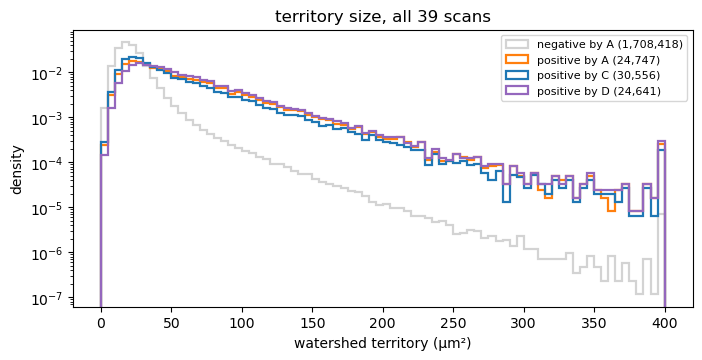

In [2]:
rows = []
for n in NAMES:
    df, s = CELLS[n], SUMMARY[n]
    beyond = df["WS beyond the nucleus (µm²)"].to_numpy(float)
    row = {"sample": n.replace("2025_09_26_Asssembloid_", ""), "cells": len(df),
           "foreground (% of tissue)": 100 * s["fg_share_of_tissue"],
           "negative by A: grown > 5 µm² past nucleus (%)": 100 * np.mean(beyond[~df[A]] > 5)}
    for rule in (A, C, D):
        chosen = df[rule].to_numpy()
        row[f"{rule[:1]}+: median territory (µm²)"] = float(np.median(df.loc[chosen, "WS area (µm²)"])) if chosen.any() else np.nan
        row[f"{rule[:1]}+: median past nucleus (µm²)"] = float(np.median(beyond[chosen])) if chosen.any() else np.nan
    row["no ring (%)"] = 100 * df["WS no ring"].mean()
    rows.append(row)
TERRITORY = pd.DataFrame(rows).set_index("sample")
display(TERRITORY.describe().loc[["mean", "50%", "min", "max"]].round(1))

pool = pd.concat(CELLS.values(), ignore_index=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0, 400, 81)
for label, chosen, colour in [("negative by A", ~pool[A], "lightgrey"), ("positive by A", pool[A], COLOURS[A]),
                              ("positive by C", pool[C], COLOURS[C]), ("positive by D", pool[D], COLOURS[D])]:
    ax.hist(pool.loc[chosen, "WS area (µm²)"].clip(upper=399), bins=bins, density=True, histtype="step", lw=1.6,
            color=colour, label=f"{label} ({int(chosen.sum()):,})")
ax.set(xlabel="watershed territory (µm²)", ylabel="density", yscale="log", title="territory size, all 39 scans")
ax.legend(fontsize=8)
plt.show()

## 2. The 39 slide scans: how many cells each rule calls, and are they the same cells?

Counts pooled over the 39 scans, in the whole section and in the junction region; **Cohen's κ** of each rule against **A** (0 chance, 1 identical) and how many of A's cells it also calls; **Spearman ρ** of the per-sample region counts against A's.

In [3]:
rows = []
for rule in RULES:
    total = sum(int(CELLS[n][rule].sum()) for n in NAMES)
    in_region = sum(int((CELLS[n][rule] & CELLS[n][ja.IN_REGION_COLUMN].astype(bool)).sum()) for n in NAMES)
    a = np.concatenate([CELLS[n][A].to_numpy() for n in NAMES])
    r = np.concatenate([CELLS[n][rule].to_numpy() for n in NAMES])
    per_a = [int((CELLS[n][A] & CELLS[n][ja.IN_REGION_COLUMN].astype(bool)).sum()) for n in NAMES]
    per_r = [int((CELLS[n][rule] & CELLS[n][ja.IN_REGION_COLUMN].astype(bool)).sum()) for n in NAMES]
    rows.append({"rule": rule, "positive (section)": total, "% of cells": 100 * r.mean(), "in region": in_region,
                 "κ vs A": kappa(r, a), "of A's cells also called (%)": 100 * (r & a).sum() / max(a.sum(), 1),
                 "of its cells also called by A (%)": 100 * (r & a).sum() / max(r.sum(), 1),
                 "Spearman ρ vs A (region, per sample)": stats.spearmanr(per_r, per_a).correlation})
AGREE = pd.DataFrame(rows).set_index("rule")
display(AGREE.round(3))

,positive (section),% of cells,in region,κ vs A,of A's cells also called (%),of its cells also called by A (%),"Spearman ρ vs A (region, per sample)"
rule,,,,,,,
"OLD: median + 3 SD (plain mean), nucleus + 3 µm",93888,5.417,6443,0.317,79.747,21.020,0.353
"A: median + 7 SD (median filter), nucleus + 3 µm",24747,1.428,557,1.000,100.000,100.000,1.000
"B: ring contrast ≥ 1.5, nucleus + 3 µm",12259,0.707,585,0.440,33.329,67.281,0.623
C: watershed ring contrast ≥ 1.5,30556,1.763,1222,0.584,65.943,53.407,0.713
D: watershed median + 7 SD (median filter),24641,1.422,520,0.807,80.794,81.141,0.962


**Thresholds of C and D.** The same comparison for other ring ratios (C) and other k (D), to see whether a different setting brings the watershed rules closer to A, or past it.

In [4]:
a = np.concatenate([CELLS[n][A].to_numpy() for n in NAMES])
rows = []
for ratio in (1.25, 1.5, 2.0, 2.5, 3.0):
    r = np.concatenate([ws_ring(CELLS[n], ratio) for n in NAMES])
    rows.append({"rule": f"C: watershed ring contrast ≥ {ratio:g}", "positive (section)": int(r.sum()),
                 "% of cells": 100 * r.mean(), "κ vs A": kappa(r, a)})
for k in (3.0, 5.0, 7.0, 10.0):
    r = np.concatenate([ws_ksd(CELLS[n], CELLS[n][ja.IN_REGION_COLUMN].astype(bool).to_numpy(), k) for n in NAMES])
    rows.append({"rule": f"D: watershed median + {k:g} SD (median filter)", "positive (section)": int(r.sum()),
                 "% of cells": 100 * r.mean(), "κ vs A": kappa(r, a)})
display(pd.DataFrame(rows).set_index("rule").round(3))

,positive (section),% of cells,κ vs A
rule,,,
C: watershed ring contrast ≥ 1.25,106421,6.140,0.331
C: watershed ring contrast ≥ 1.5,30556,1.763,0.584
C: watershed ring contrast ≥ 2,6475,0.374,0.332
C: watershed ring contrast ≥ 2.5,2470,0.143,0.159
C: watershed ring contrast ≥ 3,1314,0.076,0.088
D: watershed median + 3 SD (median filter),94026,5.425,0.391
D: watershed median + 5 SD (median filter),43641,2.518,0.666
D: watershed median + 7 SD (median filter),24641,1.422,0.807
D: watershed median + 10 SD (median filter),12787,0.738,0.650


## 3. Against Quillan's clicks

The baseline: 12 samples Quillan clicked, scored exactly as in `03_positivity_metrics` and `04_classical_vs_cellpose` — in **his region** (cells within 50 µm of his line either side, or past it); each click matched one to one to the nearest cell of `count_cells.py` within 7 µm; **TP** positive cells in the region that were clicked, **FP** positive and not clicked, **FN** clicks whose cell is not positive or that matched no cell; precision, recall, F1 pooled; per sample, positive per mm of line against clicks per mm (**Spearman**, **CCC**, **median ratio** count ÷ clicks).

The clicked samples were segmented again for this (the Cells panel's defaults, as the 39 scans); each `count_cells` cell takes the calls of the new cell nearest to it within 3 µm (none: not positive). Thresholds of A and D come from the new cells matched to Quillan's band, as the band's cells set them in `03`. The first two rows are A and OLD as `03`/`04` scored them on the `count_cells` cells — the same rules on the older segmentation, for reference.

In [5]:
import count_common as CC

cells_c, meta_c = CC.load_all(progress=False)
LABEL = CC.label_channel(meta_c)
RULES_C = CC.rules(meta_c["channels"].iloc[0], LABEL)
dots = CC.load_dots(cells_c, meta_c)
CLICKED = sorted(n for n in dots["name"].unique() if WS.done(WS.OUT_CLICKED / n))
MATCH_UM = 3.0
print(f"{len(CLICKED)} clicked samples, {int(dots['name'].isin(CLICKED).sum())} clicks")


def click_region(n):
    df = cells_c[n]
    band = "second" if "in second" in df else "first"
    reg = CC.region(df, "near + crossed", band, LABEL)
    d = dots[dots["name"] == n].copy()
    sign = -1.0 if CC.home_is_band_side(df, LABEL, band) else 1.0
    away = sign * d[f"from {band} (um)"].to_numpy()
    own = d[f"beside {band}"].to_numpy().astype(bool) & ((away > CC.GAP_UM) | (np.abs(away) <= 50))
    cell = d["cell"].to_numpy()
    d["in region"] = np.where(cell >= 0, reg[np.clip(cell, 0, None)], own)
    return band, reg, d[d["in region"]]


def matched_calls(n, band):
    # The new segmentation's calls, carried to each count_cells cell.
    df = cells_c[n]
    new = pd.read_parquet(WS.OUT_CLICKED / n / "cells.parquet")
    tree = cKDTree(new[["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy(float))
    distance, index = tree.query(df[["y (um)", "x (um)"]].to_numpy(float), distance_upper_bound=MATCH_UM)
    hit = np.isfinite(distance)
    index = np.where(hit, index, 0)
    in_band = df[f"in {band}"].to_numpy(bool)
    population = np.zeros(len(new), bool)
    population[index[hit & in_band]] = True
    filtered = new["AF488 mean (median filter)"].to_numpy(float)
    ws_filtered = new["WS AF488 mean (median filter)"].to_numpy(float)
    calls = {A: above(filtered, filtered[population], 7.0),
             B: np.nan_to_num(new["AF488 ring contrast"].to_numpy(float), nan=0.0) >= 1.5,
             C: ws_ring(new), D: above(ws_filtered, ws_filtered[population], 7.0)}
    for ratio in (1.25, 2.0, 3.0):
        calls[f"C: watershed ring contrast ≥ {ratio:g}"] = ws_ring(new, ratio)
    for k in (5.0, 10.0):
        calls[f"D: watershed median + {k:g} SD (median filter)"] = above(ws_filtered, ws_filtered[population], k)
    return {name: np.where(hit, p[index], False) for name, p in calls.items()}, float(hit.mean())


rows, matched = [], {}
for n in CLICKED:
    df = cells_c[n]
    band, reg, d = click_region(n)
    clicked = df["clicked"].to_numpy()
    cell = d["cell"].to_numpy()
    calls = {f"{A} — count_cells cells (as in 03/04)": np.asarray(RULES_C["band median + 7 SD, median filter"](df, band), bool),
             f"{OLD} — count_cells cells (as in 03/04)": np.asarray(RULES_C["band median + 3 SD (current)"](df, band), bool)}
    new_calls, matched[n] = matched_calls(n, band)
    calls.update(new_calls)
    for name, p in calls.items():
        pr = p & reg
        rows.append({"name": n, "rule": name, "mm": meta_c.loc[n, "lengths (um)"].get(band, np.nan) / 1000,
                     "TP": int((pr & clicked).sum()), "FP": int((pr & ~clicked).sum()),
                     "FN": int(((cell < 0) | ~p[np.clip(cell, 0, None)]).sum()),
                     "positive": int(pr.sum()), "clicks": len(d)})
CLICKS = pd.DataFrame(rows)
print("count_cells cells matched to a new cell within 3 µm: " + ", ".join(f"{v:.0%}" for v in matched.values()))

summary = []
for name, g in CLICKS.groupby("rule", sort=False):
    tp, fp, fn = g["TP"].sum(), g["FP"].sum(), g["FN"].sum()
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    per_mm, clicks_mm = g["positive"] / g["mm"], g["clicks"] / g["mm"]
    summary.append({"rule": name, "positive in region": int(g["positive"].sum()), "TP": int(tp), "FP": int(fp), "FN": int(fn),
                    "precision": precision, "recall": recall, "F1": 2 * precision * recall / max(precision + recall, 1e-9),
                    "Spearman vs clicks / mm": stats.spearmanr(per_mm, clicks_mm).correlation,
                    "CCC vs clicks / mm": CC.ccc(per_mm, clicks_mm),
                    "median ratio (count ÷ clicks)": float(np.median(g["positive"] / g["clicks"].clip(lower=1)))})
CLICK_SCORES = pd.DataFrame(summary).set_index("rule")
display(CLICK_SCORES.round(3))

12 clicked samples, 822 clicks


count_cells cells matched to a new cell within 3 µm: 92%, 93%, 95%, 77%, 93%, 92%, 93%, 90%, 92%, 88%, 93%, 89%


,positive in region,TP,FP,FN,precision,recall,F1,Spearman vs clicks / mm,CCC vs clicks / mm,median ratio (count ÷ clicks)
rule,,,,,,,,,,
"A: median + 7 SD (median filter), nucleus + 3 µm — count_cells cells (as in 03/04)",1295,330,965,283,0.255,0.538,0.346,0.790,0.291,1.444
"OLD: median + 3 SD (plain mean), nucleus + 3 µm — count_cells cells (as in 03/04)",5686,348,5338,265,0.061,0.568,0.110,0.280,0.034,7.250
"A: median + 7 SD (median filter), nucleus + 3 µm",1175,297,878,316,0.253,0.485,0.332,0.762,0.324,1.264
"B: ring contrast ≥ 1.5, nucleus + 3 µm",2327,196,2131,417,0.084,0.320,0.133,0.469,0.105,2.183
C: watershed ring contrast ≥ 1.5,4472,295,4177,318,0.066,0.481,0.116,0.531,0.055,4.440
D: watershed median + 7 SD (median filter),1116,293,823,320,0.263,0.478,0.339,0.783,0.318,1.203
C: watershed ring contrast ≥ 1.25,16212,408,15804,205,0.025,0.666,0.048,0.524,0.014,19.522
C: watershed ring contrast ≥ 2,933,156,777,457,0.167,0.254,0.202,0.566,0.277,0.448
C: watershed ring contrast ≥ 3,144,64,80,549,0.444,0.104,0.169,0.648,0.298,0.049


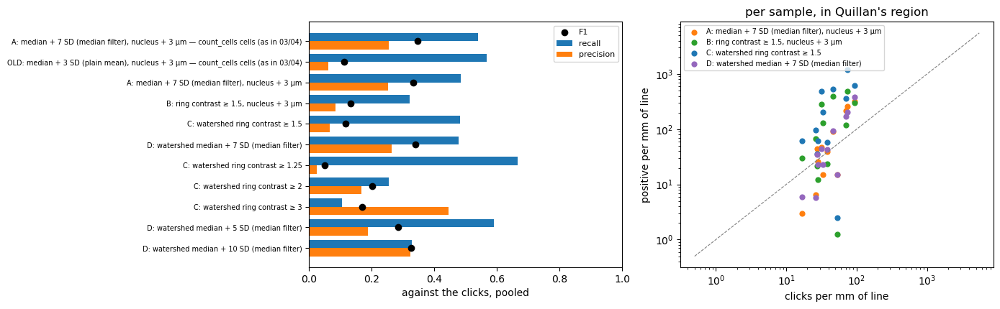

In [6]:
main = [A, B, C, D]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
order = list(CLICK_SCORES.index)
y = np.arange(len(order))
axes[0].barh(y - 0.2, CLICK_SCORES["recall"], 0.4, label="recall")
axes[0].barh(y + 0.2, CLICK_SCORES["precision"], 0.4, label="precision")
axes[0].scatter(CLICK_SCORES["F1"], y, color="black", zorder=3, label="F1")
axes[0].set(yticks=y, yticklabels=order, xlabel="against the clicks, pooled", xlim=(0, 1))
axes[0].tick_params(axis="y", labelsize=7)
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
for name in main:
    g = CLICKS[CLICKS["rule"] == name]
    axes[1].scatter(g["clicks"] / g["mm"], g["positive"] / g["mm"], color=COLOURS[name], label=name, s=24)
lim = [0.5, float((CLICKS["positive"] / CLICKS["mm"]).max()) * 1.3]
axes[1].plot(lim, lim, color="grey", lw=0.8, ls="--")
axes[1].set(xscale="log", yscale="log", xlabel="clicks per mm of line", ylabel="positive per mm of line",
            title="per sample, in Quillan's region")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 4. Pictures

For three of the slide scans, two 300 µm crops: where **A** (median + 7 SD (median filter), nucleus + 3 µm) and **C** (watershed ring contrast ≥ 1.5) disagree most, and where A's positive cells are densest. Same contrast in every panel; AF488 green, nuclei blue.

Panels: the raw image · **A** (nucleus outlined, yellow) · **B** ring contrast ≥ 1.5, nucleus + 3 µm (cyan) · every **watershed territory** (white; a territory larger than its nucleus is a cell grown over its label) · **C** watershed ring contrast ≥ 1.5 (territory outlined, magenta) · **D** watershed median + 7 SD (median filter) (territory outlined, orange).

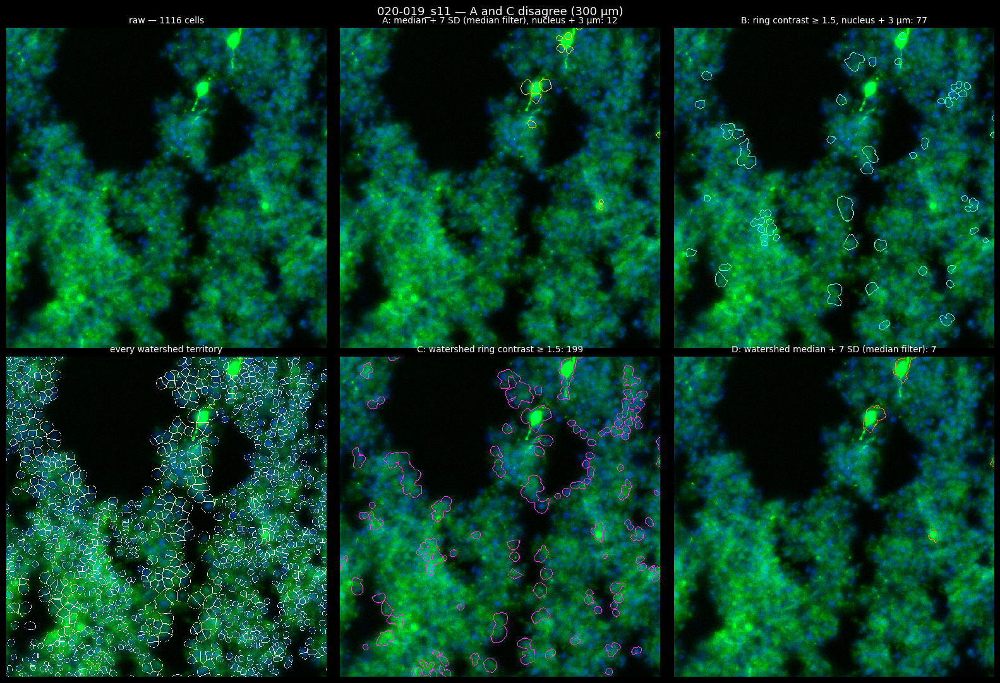

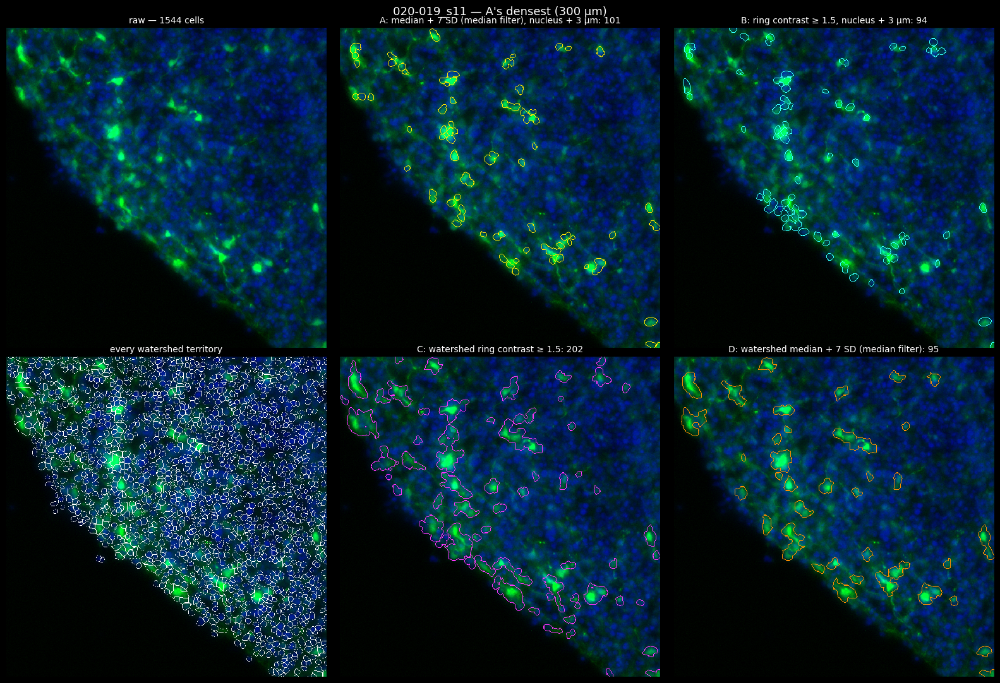

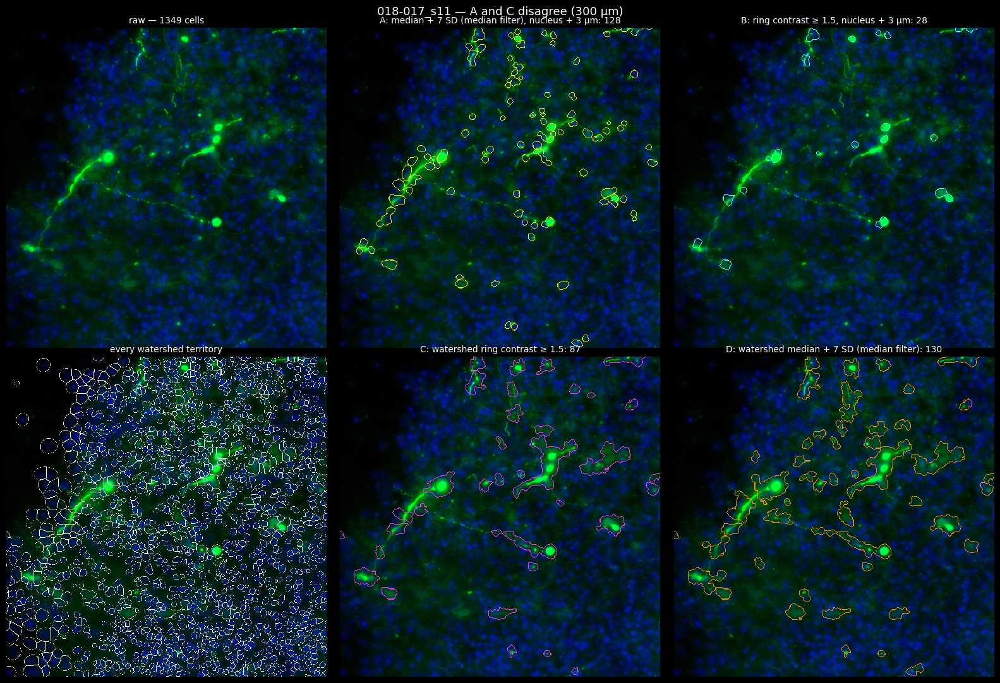

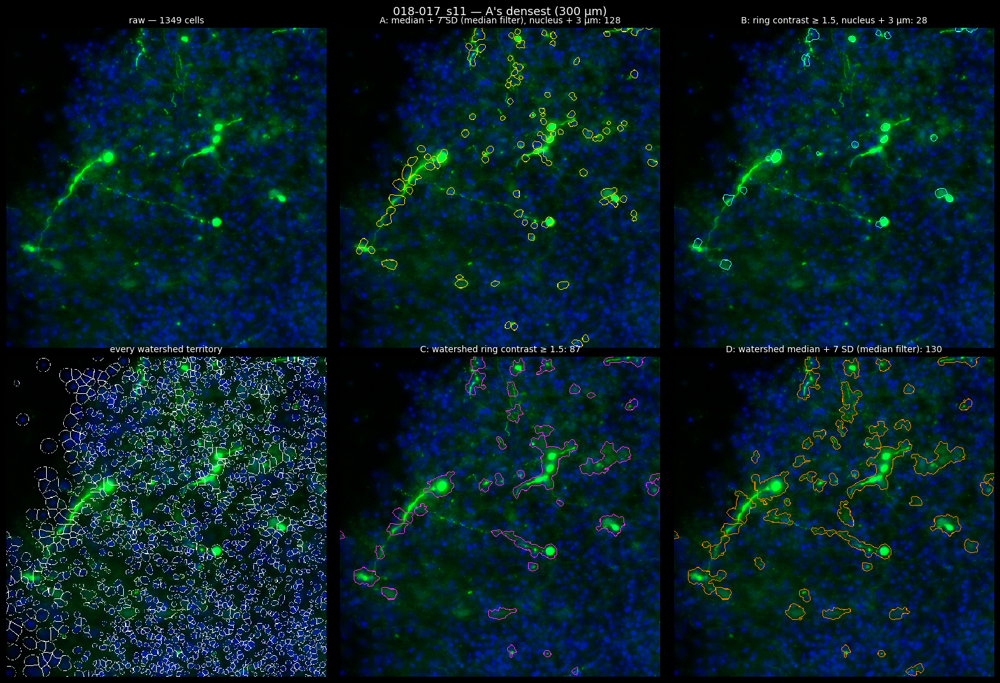

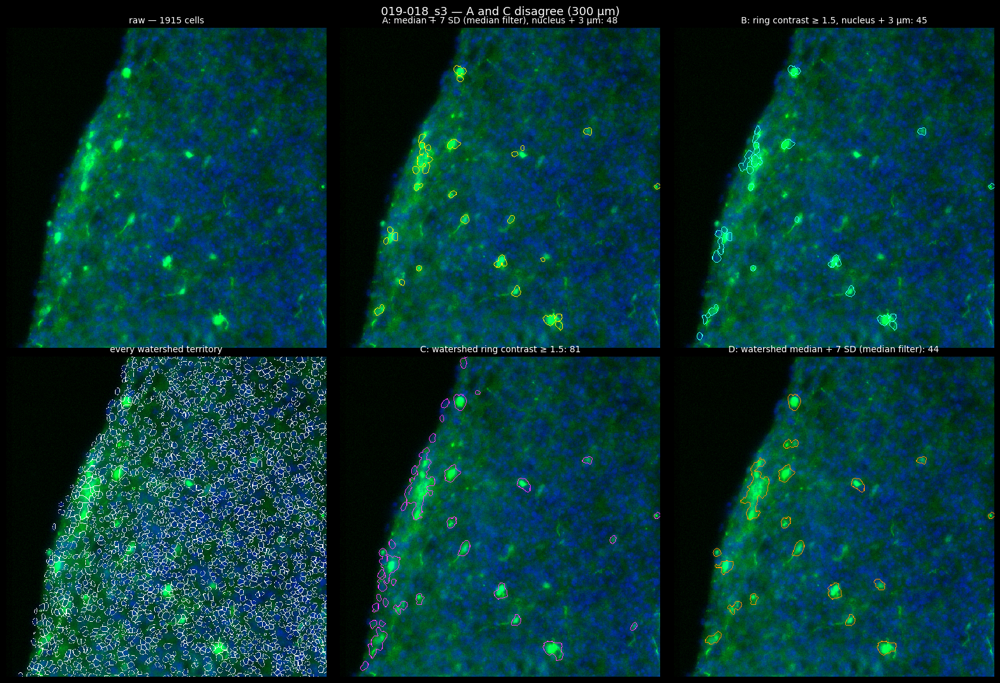

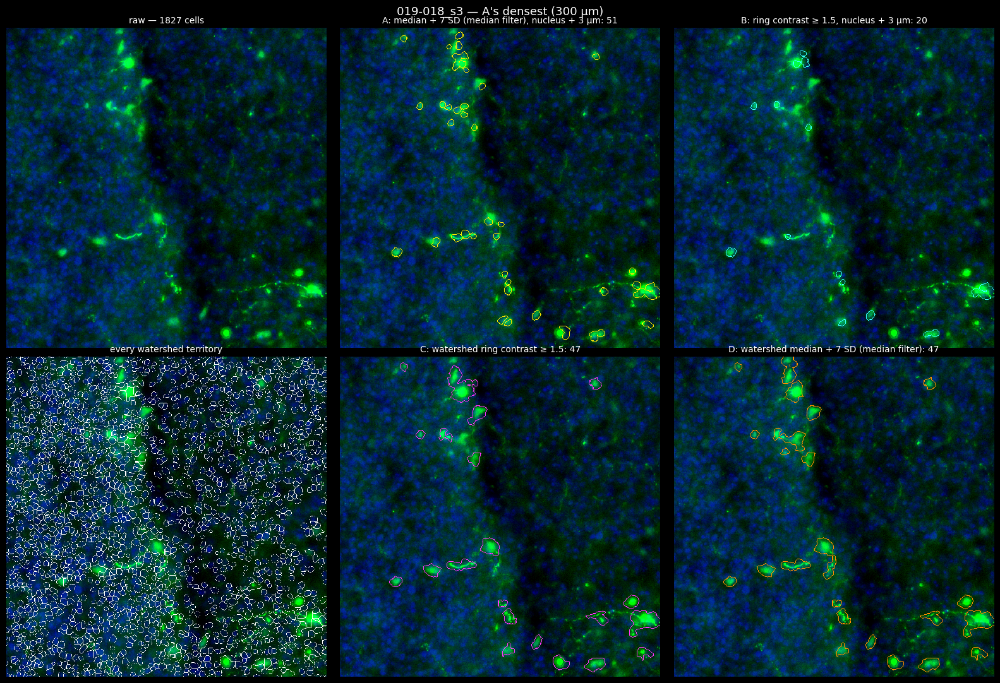

In [7]:
import tifffile
from scipy import ndimage
from skimage.segmentation import find_boundaries

CROP_UM = 300.0
SAVED = ja.segmented_samples(WS.cv.DATA)


def best_window(df, score, voxel, shape, size):
    ys = (df["Centroid Y (µm)"].to_numpy() / voxel).astype(int)
    xs = (df["Centroid X (µm)"].to_numpy() / voxel).astype(int)
    best, where = -np.inf, (0, 0)
    for y0 in range(0, max(shape[0] - size, 1), size // 2):
        for x0 in range(0, max(shape[1] - size, 1), size // 2):
            inside = (ys >= y0) & (ys < y0 + size) & (xs >= x0) & (xs < x0 + size)
            value = float(score[inside].sum())
            if value > best:
                best, where = value, (y0, x0)
    return slice(where[0], where[0] + size), slice(where[1], where[1] + size)


def edges(labels, chosen):
    mask = np.where(np.isin(labels, chosen), labels, 0)
    return ndimage.binary_dilation(find_boundaries(mask, mode="outer")) & (mask == 0)


def show(n, picks=2):
    df = CELLS[n]
    sample = SAVED[n]
    af488, nuclear, voxel, _channel = WS.read_planes(sample.path)
    nuclei = ja.read_labels(sample.file("nuclei_file"))
    territory = tifffile.imread(WS.OUT / n / "territories.tif").astype(np.int32)
    size = int(CROP_UM / voxel)
    a, c = df[A].to_numpy(float), df[C].to_numpy(float)
    windows = {"A and C disagree": best_window(df, np.abs(a - c), voxel, nuclei.shape, size),
               "A's densest": best_window(df, a, voxel, nuclei.shape, size)}
    for kind, window in list(windows.items())[:picks]:
        g, b = af488[window], nuclear[window].astype(np.float32)
        g = np.clip((g - np.percentile(g, 1)) / max(np.percentile(g, 99.7) - np.percentile(g, 1), 1e-6), 0, 1)
        b = np.clip((b - np.percentile(b, 1)) / max(np.percentile(b, 99.5) - np.percentile(b, 1), 1e-6), 0, 1) * 0.6
        rgb = np.dstack([np.zeros_like(g), g, b])
        nuc, ter = nuclei[window], territory[window]
        present = np.unique(nuc[nuc > 0])
        here = df[df["Label"].isin(present)]
        calls = {rule: here.loc[here[rule], "Label"].to_numpy() for rule in RULES}
        tiles = [(rgb, f"raw — {len(present)} cells")]
        for rule, labels, colour in [(A, nuc, (1, 0.9, 0)), (B, nuc, (0.2, 1, 1))]:
            image = rgb.copy()
            image[edges(labels, calls[rule])] = colour
            tiles.append((image, f"{rule}: {len(calls[rule])}"))
        image = rgb.copy()
        image[find_boundaries(ter, mode="inner")] = (1, 1, 1)
        tiles.append((image, "every watershed territory"))
        for rule, colour in [(C, (1, 0.2, 1)), (D, (1, 0.55, 0))]:
            image = rgb.copy()
            image[edges(ter, calls[rule])] = colour
            tiles.append((image, f"{rule}: {len(calls[rule])}"))
        fig, axes = plt.subplots(2, 3, figsize=(16, 11), facecolor="black")
        for ax, (image, title) in zip(axes.ravel(), tiles):
            ax.imshow(image, interpolation="nearest")
            ax.set_title(title, color="white", fontsize=10)
            ax.axis("off")
        fig.suptitle(f"{n.replace('2025_09_26_Asssembloid_', '')} — {kind} ({CROP_UM:.0f} µm)", color="white", fontsize=13)
        plt.tight_layout()
        plt.show()


by_disagreement = sorted(NAMES, key=lambda n: -float((CELLS[n][A] != CELLS[n][C]).mean()))
for n in [by_disagreement[0], by_disagreement[len(NAMES) // 2], by_disagreement[-1]]:
    show(n)

## 5. Merging A's positive cells that are one labelled body

Rule **A** (median + 7 SD (median filter), nucleus + 3 µm) calls nuclei, not cells: one big labelled cell body lying over two or three nuclei — or one cell whose nucleus Cellpose cut in two — is counted two or three times. Here those are merged with the classic **distance-transform watershed on the stain alone**:

- the AF488 foreground (as in step 2 above, *without* the nuclei) and its **distance transform**: how deep each pixel lies inside the labelled stain, in µm;
- in each connected piece of foreground, the **maxima of that depth at least h µm above the dip between them** are the bodies (h-maxima), and a watershed splits the piece between them — a thick body with no neck stays one, two bodies joined by a thin bridge become two;
- each cell belongs to the body holding most of its watershed territory; **A's positive cells sharing a body are counted as one** (still called by A — merging changes the count, not who is positive).

h = 0.5, 1, 2, 3 µm (larger h: fewer, bigger bodies), and *piece* — every A-positive cell in one connected piece of stain merged, the coarsest grouping. Computed by `watershed_cells.py bodies` → `bodies.parquet` (~15 s a sample).

**Against the clicks**, per object: an object with at least one clicked cell is one **TP**, an object with none one **FP**; **FN** are the clicks on cells A does not call, plus every click beyond the first inside one object (Quillan clicked two cells there; merging them lost one). So merging is rewarded only where it joins pieces Quillan counted once.

In [8]:
GROUPINGS = ["cells (no merging)", *(f"body h={h:g}" for h in WS.BODY_H_UM), "piece"]


def objects_of(table, grouping):
    return table["Label"].to_numpy() if grouping == "cells (no merging)" else table[grouping].to_numpy()


rows = []
for n in NAMES:
    df = CELLS[n].merge(pd.read_parquet(WS.OUT / n / "bodies.parquet"), on="Label", how="left")
    for g in GROUPINGS[1:]:
        df[g] = df[g].fillna(-df["Label"]).astype(np.int64)
    pos = df[df[A]]
    region = pos[ja.IN_REGION_COLUMN].astype(bool)
    row = {"sample": n}
    for g in GROUPINGS:
        ids = objects_of(pos, g)
        row[f"{g}"] = len(np.unique(ids))
        row[f"{g} (region)"] = len(np.unique(ids[region.to_numpy()]))
    rows.append(row)
MERGED = pd.DataFrame(rows).set_index("sample")
total = MERGED.sum()
display(pd.DataFrame({"A-positive objects, 39 scans": [int(total[g]) for g in GROUPINGS],
                      "in region": [int(total[f"{g} (region)"]) for g in GROUPINGS],
                      "% of A's cells": [100 * total[g] / total["cells (no merging)"] for g in GROUPINGS]},
                     index=GROUPINGS).round(1))

,"A-positive objects, 39 scans",in region,% of A's cells
cells (no merging),24747,557,100.0
body h=0.5,14207,331,57.4
body h=1,13541,317,54.7
body h=2,12852,302,51.9
body h=3,12525,301,50.6
piece,11476,267,46.4


In [9]:
rows = []
for n in CLICKED:
    df = cells_c[n]
    band, reg, d = click_region(n)
    clicked = df["clicked"].to_numpy()
    cell = d["cell"].to_numpy()
    new = pd.read_parquet(WS.OUT_CLICKED / n / "cells.parquet").merge(
        pd.read_parquet(WS.OUT_CLICKED / n / "bodies.parquet"), on="Label", how="left")
    for g in GROUPINGS[1:]:
        new[g] = new[g].fillna(-new["Label"]).astype(np.int64)
    tree = cKDTree(new[["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy(float))
    distance, index = tree.query(df[["y (um)", "x (um)"]].to_numpy(float), distance_upper_bound=MATCH_UM)
    hit = np.isfinite(distance)
    index = np.where(hit, index, 0)
    positive = matched_calls(n, band)[0][A]
    missed = int(((cell < 0) | ~positive[np.clip(cell, 0, None)]).sum())
    chosen = positive & reg
    for g in GROUPINGS:
        ids = objects_of(new, g)[index][chosen]
        per_object = pd.Series(clicked[chosen].astype(int)).groupby(ids).sum()
        rows.append({"name": n, "grouping": g, "mm": meta_c.loc[n, "lengths (um)"].get(band, np.nan) / 1000,
                     "TP": int((per_object > 0).sum()), "FP": int((per_object == 0).sum()),
                     "FN": missed + int((per_object - 1).clip(lower=0).sum()),
                     "positive": len(per_object), "clicks": len(d)})
MERGE_CLICKS = pd.DataFrame(rows)
summary = []
for g, t in MERGE_CLICKS.groupby("grouping", sort=False):
    tp, fp, fn = t["TP"].sum(), t["FP"].sum(), t["FN"].sum()
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    per_mm, clicks_mm = t["positive"] / t["mm"], t["clicks"] / t["mm"]
    summary.append({"A: median + 7 SD (median filter), counted as": g, "objects in region": int(t["positive"].sum()),
                    "TP": int(tp), "FP": int(fp), "FN": int(fn), "precision": precision, "recall": recall,
                    "F1": 2 * precision * recall / max(precision + recall, 1e-9),
                    "Spearman vs clicks / mm": stats.spearmanr(per_mm, clicks_mm).correlation,
                    "CCC vs clicks / mm": CC.ccc(per_mm, clicks_mm),
                    "median ratio (count ÷ clicks)": float(np.median(t["positive"] / t["clicks"].clip(lower=1)))})
MERGE_SCORES = pd.DataFrame(summary).set_index("A: median + 7 SD (median filter), counted as")
display(MERGE_SCORES.round(3))

,objects in region,TP,FP,FN,precision,recall,F1,Spearman vs clicks / mm,CCC vs clicks / mm,median ratio (count ÷ clicks)
"A: median + 7 SD (median filter), counted as",,,,,,,,,,
cells (no merging),1152,297,855,316,0.258,0.485,0.337,0.783,0.332,1.264
body h=0.5,588,253,335,360,0.430,0.413,0.421,0.846,0.658,0.644
body h=1,556,249,307,364,0.448,0.406,0.426,0.846,0.685,0.634
body h=2,526,243,283,370,0.462,0.396,0.427,0.846,0.701,0.634
body h=3,509,238,271,375,0.468,0.388,0.424,0.846,0.711,0.644
piece,447,222,225,391,0.497,0.362,0.419,0.846,0.677,0.576


**Pictures.** The largest merged groups at h = 1 µm in three scans, 120 µm round each: the raw image; A's positive cells, each nucleus outlined (yellow); the same cells' watershed territories, **one colour per merged body** — territories of one colour are counted once.

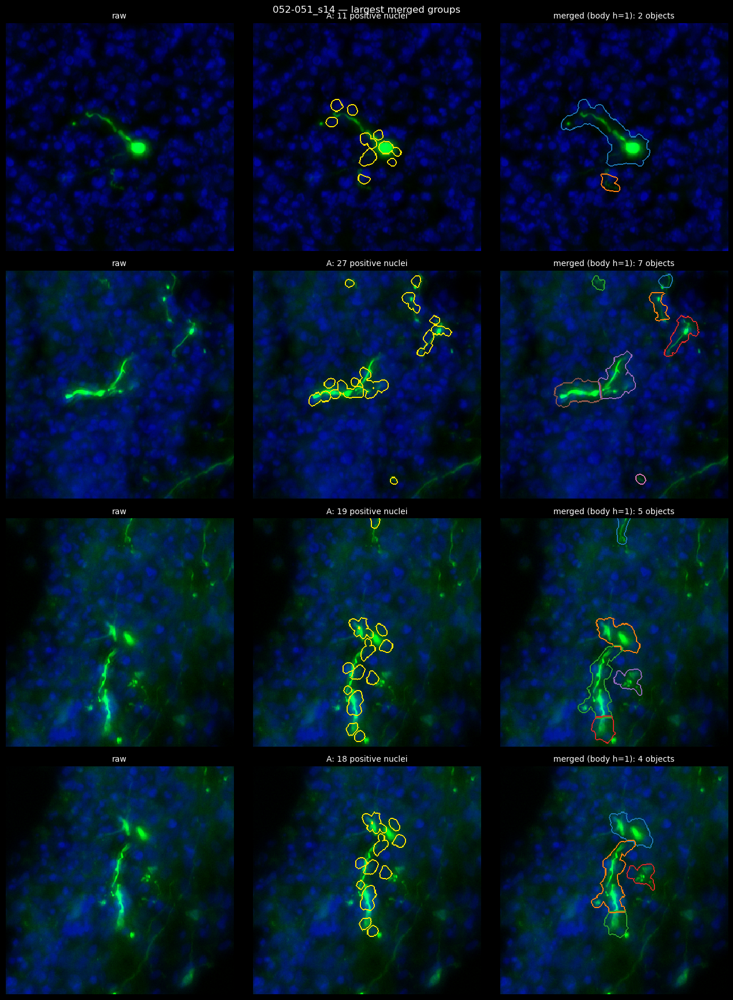

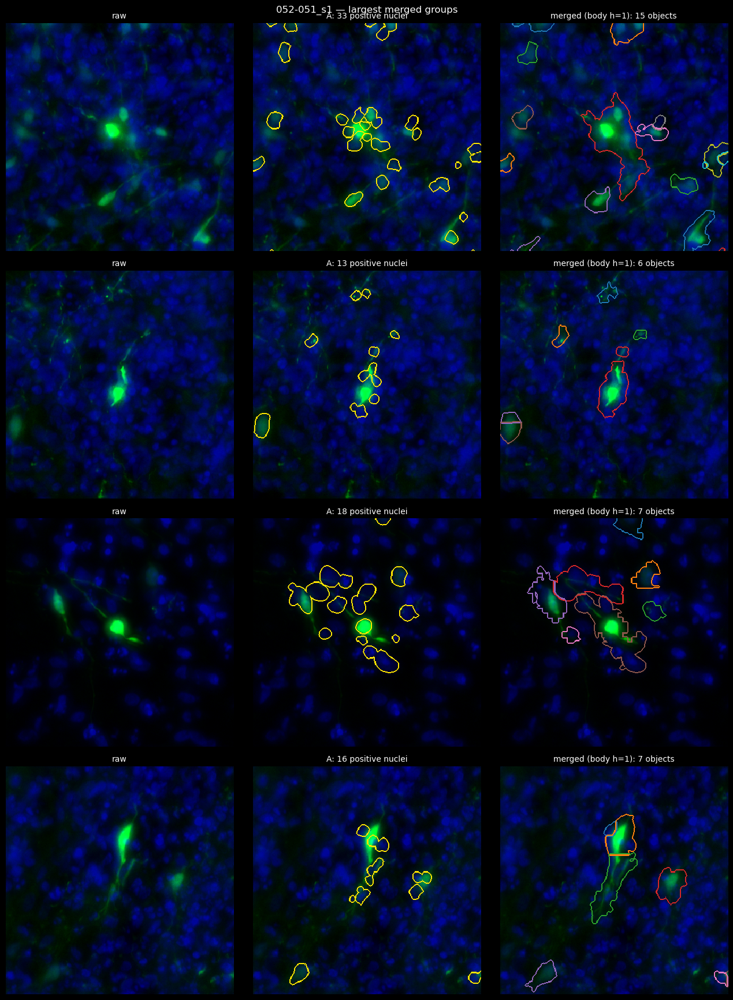

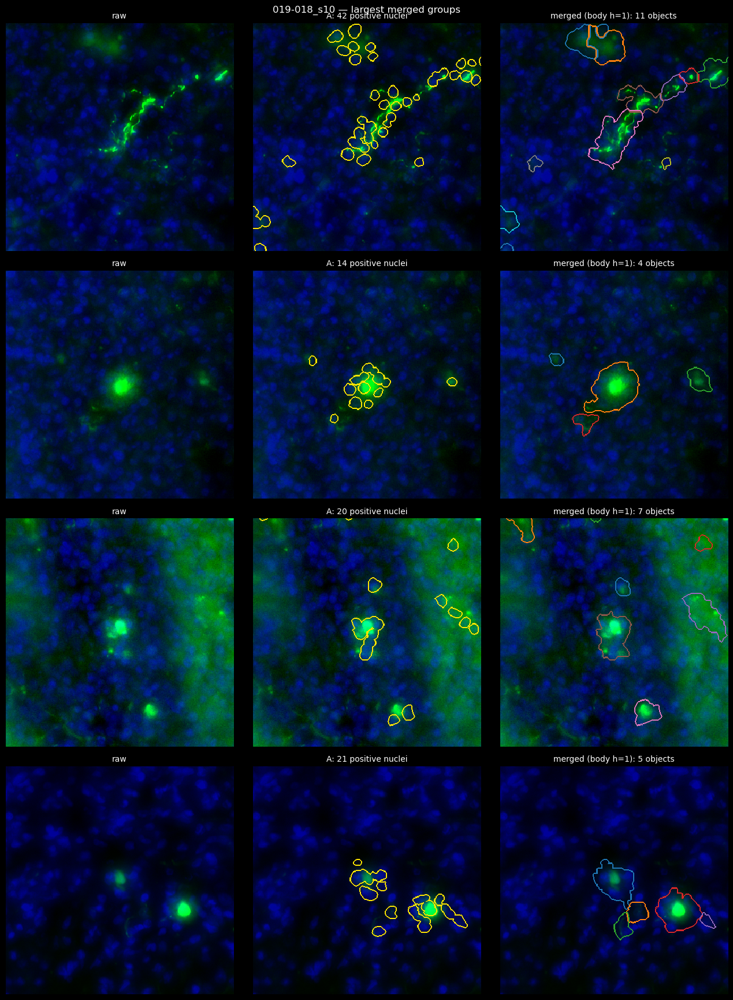

In [10]:
from matplotlib import colormaps


def merge_gallery(n, grouping="body h=1", groups=4, half_um=60.0):
    df = CELLS[n].merge(pd.read_parquet(WS.OUT / n / "bodies.parquet"), on="Label", how="left")
    pos = df[df[A]].copy()
    pos[grouping] = pos[grouping].fillna(-pos["Label"]).astype(np.int64)
    sizes = pos.groupby(grouping).size().sort_values(ascending=False)
    chosen = [b for b in sizes.index if b > 0][:groups]
    if not chosen:
        return
    sample = SAVED[n]
    af488, nuclear, voxel, _channel = WS.read_planes(sample.path)
    nuclei = ja.read_labels(sample.file("nuclei_file"))
    territory = tifffile.imread(WS.OUT / n / "territories.tif").astype(np.int32)
    half = int(half_um / voxel)
    fig, axes = plt.subplots(len(chosen), 3, figsize=(13, 4.4 * len(chosen)), facecolor="black")
    axes = np.atleast_2d(axes)
    palette = colormaps["tab10"]
    for row, body in enumerate(chosen):
        members = pos[pos[grouping] == body]
        cy = int(members["Centroid Y (µm)"].mean() / voxel)
        cx = int(members["Centroid X (µm)"].mean() / voxel)
        window = (slice(max(cy - half, 0), cy + half), slice(max(cx - half, 0), cx + half))
        g = af488[window]
        g = np.clip((g - np.percentile(g, 1)) / max(np.percentile(g, 99.8) - np.percentile(g, 1), 1e-6), 0, 1)
        b = nuclear[window].astype(np.float32)
        b = np.clip((b - np.percentile(b, 1)) / max(np.percentile(b, 99.5) - np.percentile(b, 1), 1e-6), 0, 1) * 0.6
        rgb = np.dstack([np.zeros_like(g), g, b])
        nuc, ter = nuclei[window], territory[window]
        here = pos[pos["Label"].isin(np.unique(nuc))]
        first = rgb.copy()
        first[edges(nuc, here["Label"].to_numpy())] = (1, 0.9, 0)
        second = rgb.copy()
        for k, (other, part) in enumerate(here.groupby(grouping)):
            second[edges(ter, part["Label"].to_numpy())] = palette(k % 10)[:3]
        for ax, image, title in zip(axes[row], (rgb, first, second),
                                    ("raw", f"A: {len(here)} positive nuclei",
                                     f"merged ({grouping}): {here[grouping].nunique()} objects")):
            ax.imshow(image, interpolation="nearest")
            ax.set_title(title, color="white", fontsize=10)
            ax.axis("off")
    fig.suptitle(f"{n.replace('2025_09_26_Asssembloid_', '')} — largest merged groups", color="white", fontsize=12)
    plt.tight_layout()
    plt.show()


by_merging = sorted(NAMES, key=lambda n: MERGED.loc[n, "body h=1"] / max(MERGED.loc[n, "cells (no merging)"], 1))
for n in [by_merging[0], by_merging[len(NAMES) // 2], by_merging[-1]]:
    merge_gallery(n)

### What it showed (29 October 2026: 39 slide scans, 1.73 million cells; clicks on 12 samples, 822 clicks)

**The watershed gives each positive cell its real body, but ring contrast on it is not a better rule. Scored by median + 7 SD (median filter), the watershed cell (D) calls almost the same cells as the current rule (A) and matches the clicks as well; scored by ring contrast ≥ 1.5 (C), it calls haze.**

The territories: a cell called positive by A grows a median 18 µm² past its nucleus (territory 45 µm² against a nucleus of ~25); only 3 % of A-negative cells grow more than 5 µm² past theirs. 4 % of the tissue is foreground.

| rule | positive, 39 scans | κ vs A | F1 vs clicks | precision | recall | Spearman vs clicks / mm |
|---|---|---|---|---|---|---|
| OLD: median + 3 SD (plain mean), nucleus + 3 µm | 93 888 (5.4 %) | 0.32 | 0.11 | 0.06 | 0.57 | 0.28 |
| **A: median + 7 SD (median filter), nucleus + 3 µm** (current default) | 24 747 (1.4 %) | — | **0.33** (0.35 on the `count_cells` cells, as in 03/04) | 0.25 | 0.49 | 0.76 |
| B: ring contrast ≥ 1.5, nucleus + 3 µm | 12 259 (0.7 %) | 0.44 | 0.13 | 0.08 | 0.32 | 0.47 |
| C: watershed ring contrast ≥ 1.5 | 30 556 (1.8 %) | 0.58 | 0.12 | 0.07 | 0.48 | 0.53 |
| **D: watershed median + 7 SD (median filter)** | 24 641 (1.4 %) | **0.81** | **0.34** | 0.26 | 0.48 | 0.78 |

- **D ≈ A.** Same number of cells, 81 % of each other's, ρ 0.96 per sample in the region, and the same score against the clicks (F1 0.34 vs 0.33, ρ 0.78 vs 0.76). Measuring over the whole labelled body instead of nucleus + 3 µm does not change who is positive — the median filter and the 7 SD do the work — but the pictures show D's outline following each cell's body and the base of its processes.
- **C is worse than A at every ratio.** At 1.5 the ring of a territory in dense, evenly labelled tissue is as bright as the territory's edges only on one side, and whole patches of haze come out (pictures: the A-and-C-disagree crops); precision 0.07. Raising the ratio trades recall for precision without passing A: F1 0.20 at 2, 0.17 at 3. Growing the cell over its label pulls the brightest pixels into the cell *and* leaves the ring in dimmer tissue, which flatters any cell in a gradient. The nucleus-based ring (B) has the opposite problem (its ring sits on the cell's own cytoplasm) and is no better (F1 0.13).
- D's k: 5 SD raises recall (0.59) at a loss of precision (F1 0.29); 10 SD the reverse (F1 0.33, CCC 0.61 — the closest level to the clicks of any rule).

**Merging A's positive cells that are one body (section 5) is the real gain.** Rule A counts nuclei: a bright labelled cell lights up the 3 µm round its neighbours' nuclei too, and is counted 5–9 times (pictures: one neuron, a ring of "positive nuclei"). Merging A's positive cells whose territories lie in one body of the distance-transform watershed of the stain:

| A: median + 7 SD (median filter), counted as | objects, 39 scans | F1 vs clicks | precision | recall | Spearman | CCC | count ÷ clicks |
|---|---|---|---|---|---|---|---|
| cells (no merging) | 24 747 | 0.34 | 0.26 | 0.49 | 0.78 | 0.33 | 1.26 |
| body h = 0.5 µm | 14 207 | 0.42 | 0.43 | 0.41 | 0.85 | 0.66 | 0.64 |
| **body h = 1 µm** | 13 541 | **0.43** | 0.45 | 0.41 | **0.85** | **0.69** | 0.63 |
| body h = 2 µm | 12 852 | 0.43 | 0.46 | 0.40 | 0.85 | 0.70 | 0.63 |
| body h = 3 µm | 12 525 | 0.42 | 0.47 | 0.39 | 0.85 | 0.71 | 0.64 |
| piece (all touching stain) | 11 476 | 0.42 | 0.50 | 0.36 | 0.85 | 0.68 | 0.58 |

Merging roughly halves the count (to 55 % at h = 1 µm), and the best F1 any rule has reached against the clicks rises from 0.35 to 0.43; the per-sample agreement with the clicks (CCC) doubles, 0.33 → 0.69. It costs 48 clicks of recall (two clicked cells inside one merged body) against 548 fewer false positives. h hardly matters between 0.5 and 3 µm; merging every touching piece of stain merges too far (recall 0.36).

**Decision.** Count A's positive cells as **merged bodies (h = 1 µm)** — the clearest improvement of the counts so far; a candidate for the Cells panel (a column *Positive objects* beside the cells, ~35 s a slide scan of CPU). The rest: Keep A as the rule. D is a candidate replacement for the *outline* of positive cells (today the stain's own 5 SD mask, `positive_shapes`): it gives one territory per cell, split between touching cells, from the same median-filtered channel that calls them. Ring contrast is not worth pursuing on either kind of cell. Nothing changed in the analysis.
